# On-target and trans effects in K562 essential-wide CRISPRi
Estimate construct-level responses in 100 perturbations from the [Replogle K562 essential-wide dataset](https://doi.org/10.25452/figshare.plus.20029387.v1). This subset retains 64 cells per targeting construct, 1,024 non-targeting cells and 256 genes, including all 100 on-target genes and the GATA1 targets used in the power tutorial. Work from `docs/tutorials/`.

## Screen design
Each retained cell has one construct assignment. The baseline uses the non-targeting cells across the original `gem_group` batches. The RNA size factor comes from the deposited whole-library UMI total.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import mudata
import numpy as np
import pandas as pd

source = Path("inputs/replogle.h5ad")
run = Path("runs/replogle")
run.mkdir(parents=True, exist_ok=True)
fitted = run / "fitted.h5mu"

In [2]:
import anndata as ad

screen = ad.read_h5ad(source)
obs = screen.obs
control = obs.gene_transcript.str.contains("non-targeting", regex=False)
labels = obs.loc[~control, ["gene_transcript", "gene"]].drop_duplicates().set_index("gene_transcript").gene
print(f"{len(labels)} targeting constructs, {control.sum():,} control cells, {screen.n_vars} response genes")
print(f"{obs.gem_group.nunique()} batches; {obs.loc[control, 'gem_group'].nunique()} represented among controls")
obs.loc[~control].groupby("gene_transcript", observed=True).size().describe()

100 targeting constructs, 1,024 control cells, 256 response genes
48 batches; 48 represented among controls


count    100.0
mean      64.0
std        0.0
min       64.0
25%       64.0
50%       64.0
75%       64.0
max       64.0
dtype: float64

## Fit shared construct effects
Use the control-anchored test with batch and observed library size. Each construct has a single assignment label, so this fit estimates a shared construct effect for each response gene.

In [3]:
flags = """
--perturbation-key gene_transcript --control-substring non-targeting --gene-name-key gene_name
--library-size-key UMI_count --batch-covariate gem_group --guide-effect-strategy shared --crt-pool control-anchored
--size-factor-mode observed --likelihood negbin --prior normal
--num-steps-control 500 --num-steps-betas 500 --minibatch-size-control 512 --minibatch-size-betas 512
--step-size 0.01 --max-control-cells 8000 --crt --crt-mechanism propensity
--crt-tail-families saddlepoint --crt-saddlepoint-only --crt-two-sided equal-tail --crt-polish-baseline
--crt-gene-chunk-size 32 --crt-max-gather-gib 1 --crt-seed 0 --save-model-params --device cpu --no-progress-bar
"""
args = ["--input", str(source), "--out-dir", str(run), *shlex.split(flags)]
receipt = run / "teaching_command.json"
with source.open("rb") as handle:
    input_hash = hashlib.file_digest(handle, "sha256").hexdigest()
settings = {"args": args, "input_sha256": input_hash}
if fitted.exists():
    if not receipt.exists() or json.loads(receipt.read_text()) != settings:
        raise ValueError("Existing fit uses different settings. Choose a fresh run directory.")
    print(f"Using {fitted}")
else:
    # Keep the complete CLI transcript alongside the result.
    with (run / "cli.log").open("w") as log:
        result = subprocess.run([sys.executable, "-m", "perturbo.cli", *args], stdout=log, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError((run / "cli.log").read_text()[-4000:])
    receipt.write_text(json.dumps(settings, indent=2))
    print(f"Saved {fitted}")

Using runs/replogle/fitted.h5mu


## Compare on-target knockdown and selected trans responses
The left panel shows the on-target estimate for each perturbation. The right panel compares four named perturbations on a fixed response-gene set. Stars denote screen-wide BH q < 0.1 across the tested construct–gene pairs.

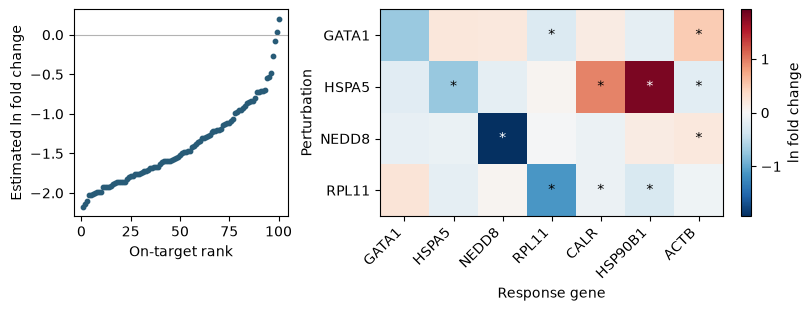

In [4]:
with mudata.set_options(pull_on_update=False):
    effects = mudata.read_h5mu(fitted).uns["_perturbo"]["effects"]
tested = effects.loc[effects.q_global.notna()].copy()
tested["target"] = tested.element.map(labels.to_dict())
on_target = tested.loc[tested.target.eq(tested.gene)].sort_values("posterior_mean")
rows = ["GATA1", "HSPA5", "NEDD8", "RPL11"]
columns = ["GATA1", "HSPA5", "NEDD8", "RPL11", "CALR", "HSP90B1", "ACTB"]
block = tested.loc[tested.target.isin(rows) & tested.gene.isin(columns)]
means = block.pivot(index="target", columns="gene", values="posterior_mean").reindex(index=rows, columns=columns)
q = block.pivot(index="target", columns="gene", values="q_global").reindex(index=rows, columns=columns)

fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3), layout="constrained",
                                  gridspec_kw={"width_ratios": [1, 1.6]})
left.axhline(0, color="0.7", lw=0.8)
left.scatter(range(1, len(on_target) + 1), on_target.posterior_mean, s=10, color="#285b77")
left.set(xlabel="On-target rank", ylabel="Estimated ln fold change")
limit = np.nanmax(np.abs(means.to_numpy()))
image = right.imshow(means, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
for y, x in np.argwhere(q.to_numpy() < 0.1):
    right.text(x, y, "*", ha="center", va="center", color="white" if abs(means.iloc[y, x]) > 0.6 * limit else "black")
right.set_xticks(range(len(columns)), columns, rotation=45, ha="right")
right.set_yticks(range(len(rows)), rows)
right.set(xlabel="Response gene", ylabel="Perturbation")
fig.colorbar(image, ax=right, label="ln fold change")
plt.show()

The [regulon power tutorial](replogle_power.ipynb) uses this fit to estimate recovery under alternative cell budgets. The [full-screen commands](https://github.com/pinellolab/PerTurbo/blob/542a832346622cf3f50bba4c1327e969fc3b8229/examples/manuscript/README.md) retain the manuscript settings for each cell line.